Imports

In [22]:
# ==========================================
# 01. Imports & Environment
# ==========================================

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydicom
import torch
import torch.nn.functional as F
import torchvision
import torchxrayvision as xrv
from collections import defaultdict

from skimage.filters import threshold_otsu


# Check the ML environment
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print(
    "GPU:",
    torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None"
)

PyTorch: 2.12.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4060


Loading Data

In [23]:
# ==========================================
# 02. Project Paths & Utility Functions
# ==========================================

PROJECT_ROOT = Path.cwd().parent

ANNOTATIONS_PATH = (
    PROJECT_ROOT
    / "Data"
    / "pneumonia-challenge-annotations-adjudicated-kaggle_2018.json"
)

IMAGE_ROOT = Path(
    r"C:\XrayData\mdai_rsna_project_x9N20BZa_images_2018-07-20-153330"
)


# Verify that the expected data locations exist
print("Project root:", PROJECT_ROOT)
print("Annotations exist:", ANNOTATIONS_PATH.exists())
print("Image dataset exists:", IMAGE_ROOT.exists())


# Load pixel data from a DICOM file
def load_dicom_image(path):
    dicom = pydicom.dcmread(path)
    image = dicom.pixel_array

    # Handle inverted grayscale images if necessary
    if getattr(dicom, "PhotometricInterpretation", "") == "MONOCHROME1":
        image = image.max() - image

    return image



# ==========================================
# Segmewntation Definitions
# ==========================================

# Otsu segmentation
def otsu_segment(image):
    threshold = threshold_otsu(image)
    mask = image > threshold

    # Keep the selected pixels and remove the rest
    segmented = image.copy()
    segmented[~mask] = 0

    return segmented

Project root: c:\Users\jtmor\GitHub\chest-xray-pneumonia-detection
Annotations exist: True
Image dataset exists: True


In [19]:
# ==========================================
# 03. Load Annotation Data
# ==========================================

with open(ANNOTATIONS_PATH, "r", encoding="utf-8") as f:
    annotations_data = json.load(f)


# Extract the main dataset from the md.ai export
dataset_data = annotations_data["datasets"][0]

studies = dataset_data["studies"]
annotations = dataset_data["annotations"]


print("Studies:", len(studies))
print("Annotations:", len(annotations))

Studies: 30000
Annotations: 83809


Data Separation

In [6]:
# ==========================================
# 04. Select Annotation Group
# ==========================================

# Find the annotation groups from the md.ai export
label_groups = annotations_data["labelGroups"]

# The "Calculated" group contains the consolidated labels
calculated_group = next(
    group for group in label_groups
    if group["name"] == "Calculated"
)

# Keep the remaining groups separate for reference only
chill_label_groups = [
    group for group in label_groups
    if group["name"] != "Calculated"
]


# Store only the labels we will use for classification
calculated_labels = {
    label["id"]: label["name"]
    for label in calculated_group["labels"]
}

print("Labels used for classification:")
for label_id, label_name in calculated_labels.items():
    print(f"- {label_name}: {label_id}")

print("\n annotation groups chilling in the back:", [g["name"] for g in chill_label_groups])

Labels used for classification:
- Normal: L_o8w
- No Lung Opacity / Not Normal: L_yd0
- Lung Opacity: L_v8n

 annotation groups chilling in the back: ['Default group', 'QA', 'Team 1', 'Team 2', 'Team 2a', 'Adjudication']


In [7]:
# ==========================================
# 05. Extract Calculated Annotations
# ==========================================

calculated_annotations = [
    annotation
    for annotation in annotations
    if annotation["labelId"] in calculated_labels
]

print("Calculated annotations:", len(calculated_annotations))

Calculated annotations: 33968


In [9]:
# ==========================================
# 06. Build Image-Level Dataset
# ==========================================

# Group all Calculated labels by image
image_labels = defaultdict(set)

for annotation in calculated_annotations:
    image_id = annotation["SOPInstanceUID"]
    label = calculated_labels[annotation["labelId"]]
    image_labels[image_id].add(label)


# Every image should have exactly one clinical label
invalid_images = {
    image_id: labels
    for image_id, labels in image_labels.items()
    if len(labels) != 1
}

print("Unique labelled images:", len(image_labels))
print("Images with conflicting labels:", len(invalid_images))

dataset = pd.DataFrame(
    {
        "SOPInstanceUID": image_id,
        "label": next(iter(labels)),
    }
    for image_id, labels in image_labels.items()
)

# Convert the three clinical categories into our binary classification target
label_mapping = {
    "Normal": 0,
    "No Lung Opacity / Not Normal": 0,
    "Lung Opacity": 1,
}

dataset["target"] = dataset["label"].map(label_mapping)


print("Dataset shape:", dataset.shape)
print("\nTarget distribution:")
print(dataset["target"].value_counts())
print("\nMissing targets:", dataset["target"].isna().sum())

dataset.head()

Unique labelled images: 29684
Images with conflicting labels: 0
Dataset shape: (29684, 3)

Target distribution:
target
0    22578
1     7106
Name: count, dtype: int64

Missing targets: 0


,SOPInstanceUID,label,target
0,1.2.276.0.7230010.3.1.4.8323329.20779.15178744...,No Lung Opacity / Not Normal,0
1,1.2.276.0.7230010.3.1.4.8323329.19863.15178744...,No Lung Opacity / Not Normal,0
2,1.2.276.0.7230010.3.1.4.8323329.12963.15178743...,No Lung Opacity / Not Normal,0
3,1.2.276.0.7230010.3.1.4.8323329.29425.15178744...,No Lung Opacity / Not Normal,0
4,1.2.276.0.7230010.3.1.4.8323329.13765.15178743...,No Lung Opacity / Not Normal,0


In [10]:
# ==========================================
# 07. Map DICOM Files & X-ray View
# ==========================================

# Find all DICOM files in the extracted dataset
dcm_files = list(IMAGE_ROOT.rglob("*.dcm"))

# Map SOPInstanceUID → DICOM file path
dcm_paths = {
    file.stem: file
    for file in dcm_files
}

dataset["path"] = dataset["SOPInstanceUID"].map(dcm_paths)


# Read the acquisition view from each DICOM
def get_view_position(path):
    ds = pydicom.dcmread(path, stop_before_pixels=True)
    return getattr(ds, "ViewPosition", "MISSING")


dataset["ViewPosition"] = dataset["path"].apply(get_view_position)


# Verify the mapping and view information
print("DICOM files found:", len(dcm_files))
print("Missing DICOM paths:", dataset["path"].isna().sum())

print("\nView distribution:")
print(dataset["ViewPosition"].value_counts())

DICOM files found: 30000
Missing DICOM paths: 0

View distribution:
ViewPosition
PA    16129
AP    13555
Name: count, dtype: int64


In [16]:
# ==========================================
# Sushi Step: separate into variables for later use
# ==========================================

# Separate the three clinical categories
Norm = dataset[dataset["label"] == "Normal"].copy()

Lu_Op = dataset[dataset["label"] == "Lung Opacity"].copy()

NLO_NN = dataset[
    dataset["label"] == "No Lung Opacity / Not Normal"
].copy()


# Separate each category by X-ray viewpoint
Norm_AP = Norm[Norm["ViewPosition"] == "AP"].copy()
Norm_PA = Norm[Norm["ViewPosition"] == "PA"].copy()

Lu_Op_AP = Lu_Op[Lu_Op["ViewPosition"] == "AP"].copy()
Lu_Op_PA = Lu_Op[Lu_Op["ViewPosition"] == "PA"].copy()

NLO_NN_AP = NLO_NN[NLO_NN["ViewPosition"] == "AP"].copy()
NLO_NN_PA = NLO_NN[NLO_NN["ViewPosition"] == "PA"].copy()


# Display the number of images in each group
print("Normal:", len(Norm))
print("  AP:", len(Norm_AP))
print("  PA:", len(Norm_PA))

print("\nLung Opacity:", len(Lu_Op))
print("  AP:", len(Lu_Op_AP))
print("  PA:", len(Lu_Op_PA))

print("\nNo Lung Opacity / Not Normal:", len(NLO_NN))
print("  AP:", len(NLO_NN_AP))
print("  PA:", len(NLO_NN_PA))


Normal: 9790
  AP: 1795
  PA: 7995

Lung Opacity: 7106
  AP: 5492
  PA: 1614

No Lung Opacity / Not Normal: 12788
  AP: 6268
  PA: 6520


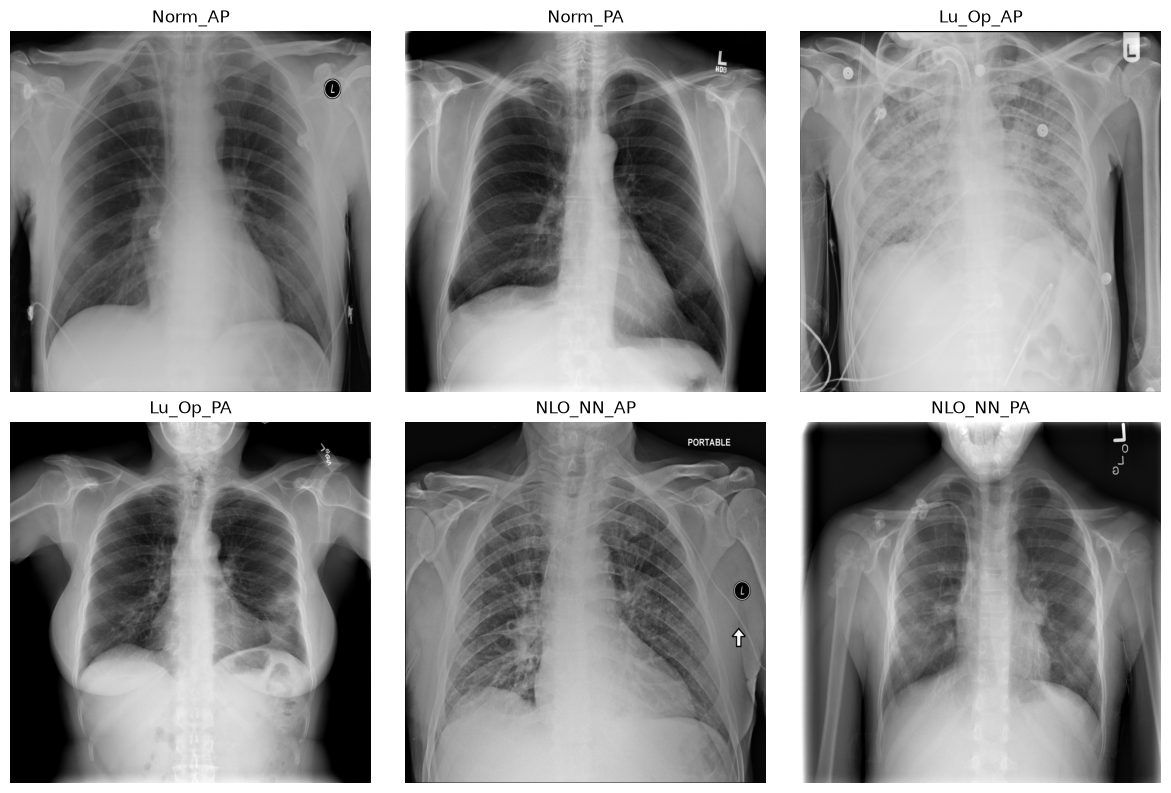

In [21]:
# ==========================================
# Sushi Sanity Check: How is it looking? Goodlooking ;)
# ==========================================

groups = {
    "Norm_AP": Norm_AP,
    "Norm_PA": Norm_PA,
    "Lu_Op_AP": Lu_Op_AP,
    "Lu_Op_PA": Lu_Op_PA,
    "NLO_NN_AP": NLO_NN_AP,
    "NLO_NN_PA": NLO_NN_PA,
}


fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (group_name, group_data) in zip(axes.ravel(), groups.items()):
    sample = group_data.sample(1).iloc[0]
    image = load_dicom_image(sample["path"])

    ax.imshow(image, cmap="gray")
    ax.set_title(group_name)
    ax.axis("off")

plt.tight_layout()
plt.show()